<a href="https://colab.research.google.com/github/aymanr8-dot/ds2002-fa26/blob/main/notebooks/07-visualization/2026_11_13_%E2%80%94_Visualization_Challenge_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

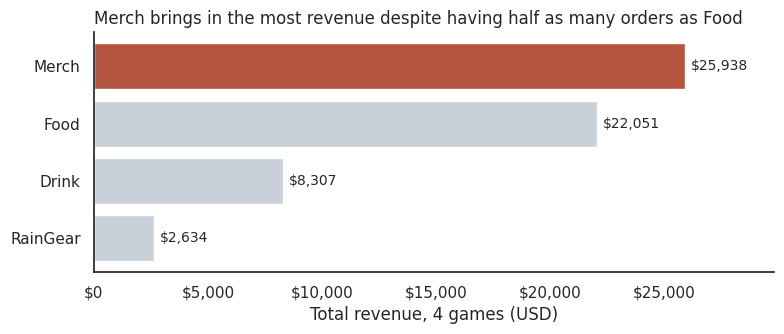

In [2]:
from matplotlib.ticker import StrMethodFormatter

by_cat = df.groupby('category')['revenue'].sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.5))
colors = [RUST if c == by_cat.idxmax() else GRAY for c in by_cat.index]
ax.barh(by_cat.index, by_cat.values, color=colors)
ax.set_xlim(0, by_cat.max() * 1.15)
ax.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
for y, v in enumerate(by_cat.values):
    ax.text(v + by_cat.max() * 0.01, y, f'${v:,.0f}', va='center', fontsize=10)
finish(ax, 'Merch brings in the most revenue despite having half as many orders as Food',
       xlabel='Total revenue, 4 games (USD)')
ax.set_ylabel('')
plt.show()


**Caption:** Merch is the biggest earner (~$25.9k over 4 games) on about half as many orders as Food, so protecting merch stock and stand placement matters more than adding food lines.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

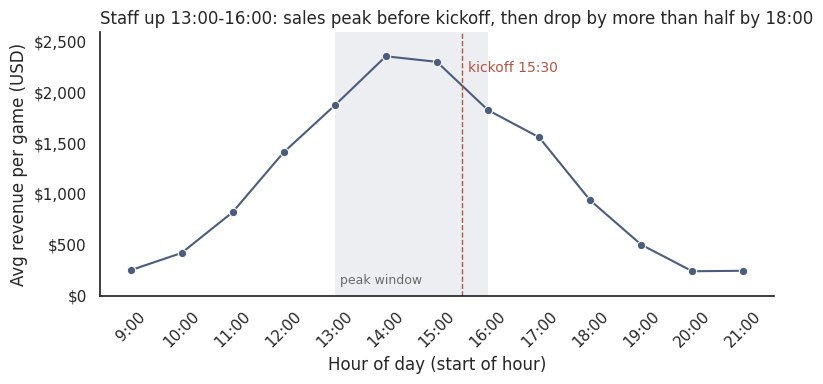

In [3]:
KICKOFF = 15.5
n_games = df['game'].nunique()
by_hour = (df.groupby('hour')['revenue'].sum() / n_games).reset_index()

fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=by_hour, x='hour', y='revenue', color=BLUE, marker='o', ax=ax)
ax.axvline(KICKOFF, color=RUST, ls='--', lw=1)
ax.text(KICKOFF + 0.1, by_hour['revenue'].max() * 0.98, 'kickoff 15:30',
        color=RUST, fontsize=10, va='top')
ax.axvspan(13, 16, color=GRAY, alpha=0.35, lw=0)
ax.text(13.1, 120, 'peak window', fontsize=9, color='dimgray')
ax.set_ylim(0, by_hour['revenue'].max() * 1.1)
ax.set_xticks(range(9, 22))
ax.set_xticklabels([f'{h}:00' for h in range(9, 22)], rotation=45)
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
finish(ax, 'Staff up 13:00-16:00: sales peak before kickoff, then drop by more than half by 18:00',
       xlabel='Hour of day (start of hour)', ylabel='Avg revenue per game (USD)')
plt.show()


**Caption:** Revenue climbs from opening, peaks at 14:00–15:00 just before the 15:30 kickoff, and falls off after 17:00 — schedule the most stand staff for 13:00–16:00 and start sending people home after 18:00.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

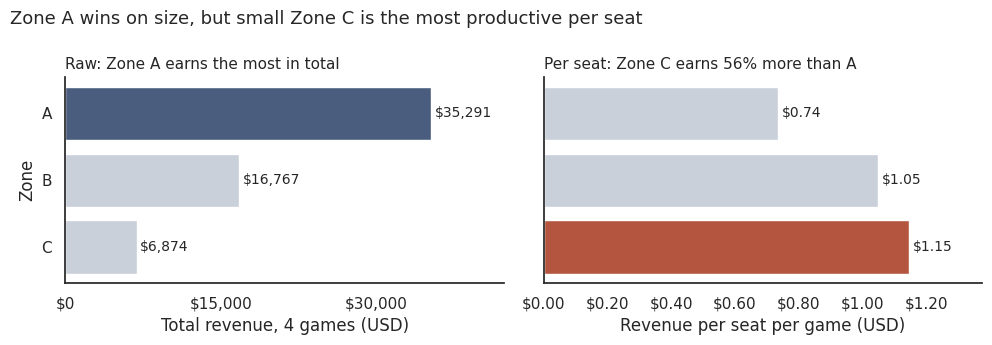

,revenue,capacity,rev_per_seat
zone,,,
A,35290.90,12000,0.74
B,16766.58,4000,1.05
C,6873.73,1500,1.15


In [4]:
from matplotlib.ticker import StrMethodFormatter

zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
n_games = df['game'].nunique()

zones = pd.DataFrame({'revenue': df.groupby('zone')['revenue'].sum()})
zones['capacity'] = pd.Series(zone_capacity)
zones['rev_per_seat'] = zones['revenue'] / zones['capacity'] / n_games

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)

raw = zones['revenue'].sort_values()
ax1.barh(raw.index, raw.values, color=[BLUE if z == 'A' else GRAY for z in raw.index])
ax1.set_xlim(0, raw.max() * 1.2)
ax1.xaxis.set_major_locator(plt.MaxNLocator(4))
ax1.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
for y, v in enumerate(raw.values):
    ax1.text(v + raw.max() * 0.01, y, f'${v:,.0f}', va='center', fontsize=10)
finish(ax1, 'Raw: Zone A earns the most in total', xlabel='Total revenue, 4 games (USD)',
       ylabel='Zone', fontsize=11)

per = zones['rev_per_seat'].reindex(raw.index)
ax2.barh(per.index, per.values, color=[RUST if z == 'C' else GRAY for z in per.index])
ax2.set_xlim(0, per.max() * 1.2)
ax2.xaxis.set_major_formatter(StrMethodFormatter('${x:,.2f}'))
for y, v in enumerate(per.values):
    ax2.text(v + per.max() * 0.01, y, f'${v:.2f}', va='center', fontsize=10)
finish(ax2, 'Per seat: Zone C earns 56% more than A', xlabel='Revenue per seat per game (USD)',
       fontsize=11)

fig.suptitle('Zone A wins on size, but small Zone C is the most productive per seat',
             x=0.01, ha='left', fontsize=13)
fig.tight_layout()
plt.show()
zones.round(2)


Which panel I would present:** Zone A brings in about 60% of all revenue, but per seat Zone C earns ~\$1.15 per game vs. ~$0.74 in A. For a manager deciding where to add stands or staff, I'd present the per-seat panel, because it shows where demand outruns capacity. For a budget or revenue-forecast question, I'd present the raw panel, because that's where the dollars actually come from.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

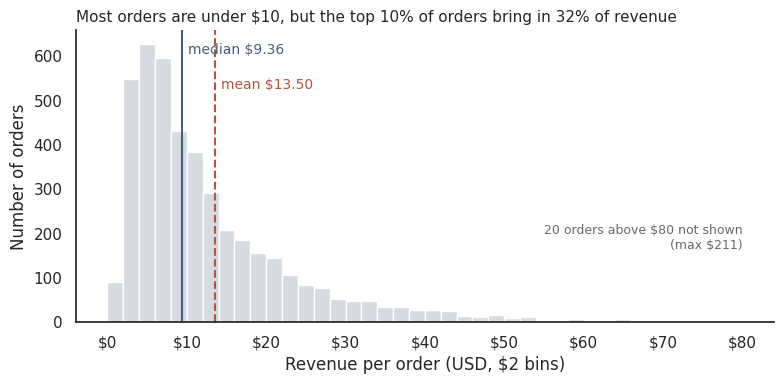

median $9.36 | mean $13.50 | skew 3.54 | top 10% of orders = 32% of revenue


In [5]:
from matplotlib.ticker import StrMethodFormatter

rev = df['revenue']
CUTOFF = 80
n_over = (rev > CUTOFF).sum()
top10_share = rev.nlargest(len(rev) // 10).sum() / rev.sum()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(rev[rev <= CUTOFF], binwidth=2, binrange=(0, CUTOFF), color=GRAY,
             edgecolor='white', ax=ax)
ax.axvline(rev.median(), color=BLUE, lw=1.5)
ax.axvline(rev.mean(), color=RUST, lw=1.5, ls='--')
top = ax.get_ylim()[1]
ax.text(rev.median() + 0.8, top * 0.92, f'median ${rev.median():.2f}', color=BLUE, fontsize=10)
ax.text(rev.mean() + 0.8, top * 0.80, f'mean ${rev.mean():.2f}', color=RUST, fontsize=10)
ax.text(CUTOFF, top * 0.25,
        f'{n_over} orders above ${CUTOFF} not shown\n(max ${rev.max():.0f})',
        ha='right', fontsize=9, color='dimgray')
ax.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
finish(ax, f'Most orders are under $10, but the top 10% of orders bring in {top10_share:.0%} of revenue',
       xlabel='Revenue per order (USD, $2 bins)', ylabel='Number of orders', fontsize=11)
plt.show()
print(f'median ${rev.median():.2f} | mean ${rev.mean():.2f} | skew {rev.skew():.2f} | '
      f'top 10% of orders = {top10_share:.0%} of revenue')


Order values are strongly right-skewed: the median order is \$9.36 but the mean is $13.50, and the top 10% of orders bring in about a third of revenue. A category total hides this; the shape says a minority of big tickets (~80% of them Merch) drive revenue, so upsells and fast checkout for big baskets matter.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

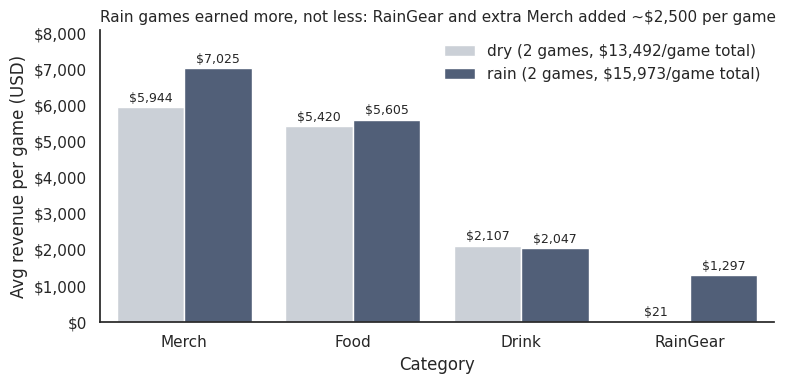

weather,dry,rain
category,,
Drink,2107.0,2047.0
Food,5420.0,5605.0
Merch,5944.0,7025.0
RainGear,21.0,1297.0


In [6]:
from matplotlib.ticker import StrMethodFormatter

n_per_weather = df.groupby('weather')['game'].nunique()
per_game = (df.groupby(['weather', 'category'])['revenue'].sum()
              .div(n_per_weather, level='weather')
              .rename('revenue').reset_index())
order = (per_game.groupby('category')['revenue'].sum()
                 .sort_values(ascending=False).index)
totals = per_game.groupby('weather')['revenue'].sum()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=per_game, x='category', y='revenue', hue='weather',
            order=order, hue_order=['dry', 'rain'],
            palette={'dry': GRAY, 'rain': BLUE}, ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt='${:,.0f}', fontsize=9, padding=2)
ax.set_ylim(0, per_game['revenue'].max() * 1.15)
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, [f"dry (2 games, ${totals['dry']:,.0f}/game total)",
                    f"rain (2 games, ${totals['rain']:,.0f}/game total)"],
          title='', frameon=False)
finish(ax, 'Rain games earned more, not less: RainGear and extra Merch added ~$2,500 per game',
       xlabel='Category', ylabel='Avg revenue per game (USD)', fontsize=11)
plt.show()
per_game.pivot(index='category', columns='weather', values='revenue').round(0)


**Caption:** Rainy games averaged \$16.0k vs. \$13.5k on dry days. Nearly all of the gap is RainGear (~\$1.3k/game) plus extra Merch, while Food and Drink barely moved, so on a rain forecast, stock RainGear and Merch rather than cutting staff.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
def rubric():
    return dict(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)

scores = {}
for name in ['chart 1 (category)', 'chart 2 (hour)', 'chart 3 (zone)',
             'chart 4 (distribution)', 'chart 5 (your choice)']:
    print(f'--- {name} ---')
    scores[name] = score(**rubric())
    print()

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')


--- chart 1 (category) ---
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

--- chart 2 (hour) ---
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

--- chart 3 (zone) ---
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

--- chart 4 (distribution) ---
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

--- chart 5 (your choice) ---
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

chart 1 (category)         6/6 

### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

a) Chart 5 changed my mind about how rain affects sales. Rainy games showed to earn about \$2500 more per game. Therefore, this challenged my perception on the data as I had expected rain to normally affects sales in a negative manner.

b) Raw revenue is the right one to show for questions regareding total dollars. This could be things such as budgets, revenue forecast, or even where a stand closure may cost the most.

Revenue per seat helps us answers questions relating to efficiency, when we are considering where to add stands or staff, or where demand may be outgoing capacity.

Raw revenue mostly tells you how big each zone is, while revenue per seat shows how strong demand is.